# Deep Learning & Neural Networks with TensorFlow / Keras

This notebook provides complete, hands-on implementations and evaluations of core **Neural Network** architectures using **TensorFlow** and the high-level **Keras API** with GPU acceleration:

1. **Basics of Neural Networks (Perceptron & Multi-Layer Perceptron)** — *MNIST Handwritten Digits (Feedforward Classification)*
   - 1.1 Single Hidden Layer Perceptron
   - 1.2 Deep Multi-Layer Perceptron (MLP) with ReLU & Dropout
2. **Convolutional Neural Networks (CNN)** — *MNIST Handwritten Digits (Spatial Feature Extraction)*
3. **Recurrent Neural Networks (RNN)** — *Sentiment Sequence Classification (Hidden State Recurrence)*
4. **Long Short-Term Memory Networks (LSTM)** — *Sentiment Analysis (Gated Long-Range Memory)*
5. **Practical Application of Neural Networks** — *CIFAR-10 Object Recognition (End-to-End Deep Pipeline with Augmentation, Callbacks & Checkpointing)*
6. **Comparative Summary & Architecture Selection Guide** (Including PyTorch vs TensorFlow Paradigm Differences)
7. **Curated Learning Resources & References** (Andrej Karpathy, 3Blue1Brown, Stanford, and Foundation Papers)

---

### Pedagogical Template (8-Step Architecture):
To maximize educational clarity for students and serve as an organized revision guide, every neural network architecture section is structured around a uniform 8-step workflow adapted for TensorFlow/Keras:
1. **Importing** — Framework classes (`tensorflow`, `tf.keras`), layer modules (`layers`), optimizers, loss functions, and evaluation utilities.
2. **Loading Dataset** — Dataset acquisition via `tf.keras.datasets`, shape inspection, sample visualization, and label exploration.
3. **Preprocessing & Data Pipelines** — Normalization, one-hot/integer label formatting, train/test splitting, and `tf.data.Dataset` batching.
4. **Model Architecture Definition** — Building models with `tf.keras.Sequential` or Functional API, configuring layers (`Dense`, `Conv2D`, `LSTM`), and inspecting `model.summary()`.
5. **Compilation & Training (Fit)** — Configuring objectives via `model.compile()` (optimizer, loss, metrics) and fitting via `model.fit()` with validation monitoring and callbacks.
6. **Predict (Inference)** — Generating predictions with `model.predict()`, decoding class probabilities via `np.argmax()`.
7. **Evaluation** — Test loss/accuracy via `model.evaluate()`, precision/recall/F1 metrics, and confusion matrix analysis.
8. **Visualization** — Training loss/accuracy curves from `history.history`, confusion matrix heatmaps, learned feature maps, and sample prediction displays.

---

### Hardware Acceleration (GPU / CPU):
TensorFlow automatically manages compute placement. When an NVIDIA GPU with CUDA/cuDNN is available, TensorFlow transparently places tensor allocations and layer computations onto GPU tensor cores.


In [14]:
# Hardware Acceleration & GPU Detection
%pip install 'tensorflow[and-cuda]'
import tensorflow as tf

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {tf.keras.__version__}")

# Check physical GPU devices
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Enable dynamic GPU memory allocation to prevent TensorFlow from allocating all VRAM upfront
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"🚀 Acceleration: {len(gpus)} Physical GPU(s) Detected:")
        for idx, gpu in enumerate(gpus):
            print(f"   [{idx}] Device: {gpu.name}")
    except RuntimeError as e:
        print(f"GPU Configuration Warning: {e}")
else:
    print("ℹ️ Compute Device: Standard CPU (No GPU acceleration detected).")


Note: you may need to restart the kernel to use updated packages.
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
ℹ️ Compute Device: Standard CPU (No GPU acceleration detected).


c:\Users\Ayush\Desktop\ACC-HPC2026-AIML\.venv\Scripts\python.exe: No module named pip


In [15]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[]


---
# 1. Basics of Neural Networks: Perceptron & Multi-Layer Perceptron (MLP)

A **Neural Network** is a universal function approximator composed of interconnected layers of computational nodes (neurons) inspired by biological nervous systems.

### Biological to Artificial Neuron Mapping:
- **Dendrites (Inputs):** Input features $x_1, x_2, \dots, x_n$.
- **Synapses (Weights):** Learnable connection strengths $w_1, w_2, \dots, w_n$ that scale incoming signals.
- **Soma (Cell Body):** Weighted summation plus a threshold bias:
  $$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$
- **Axon (Output & Activation):** Passes the aggregated sum through a non-linear activation function $\sigma(z)$ to generate output activation $a$:
  $$a = \sigma(z)$$

### Core Activation Functions:
1. **Sigmoid:**
   $$\sigma(z) = \frac{1}{1 + e^{-z}} \in (0, 1)$$
   Used historically in hidden layers; now primarily for binary classification outputs. Prone to vanishing gradients when $|z|$ is large.
2. **Rectified Linear Unit (ReLU):**
   $$\text{ReLU}(z) = \max(0, z)$$
   The modern standard for hidden layers. Avoids gradient saturation for positive activations and allows rapid, computationally efficient convergence.
3. **Softmax (Multi-Class Output):**
   $$\text{Softmax}(z_k) = \frac{e^{z_k}}{\sum_{j=1}^{C} e^{z_j}}$$
   Normalizes unconstrained logits $z$ into a valid probability distribution over $C$ mutually exclusive classes.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine an orchestra where musicians are seated in rows. The front row (input layer) hears the conductor's cue. Each musician plays a note and adjusts their volume based on how loud their neighbor was playing (weights). The musicians in the middle rows (hidden layers) combine what they hear from the row ahead, blend the harmonies, and pass it back. The back row (output layer) produces the final grand chord. When the audience applauds or winces (the loss function), a critic walks backward through the orchestra (backpropagation), tapping individual musicians on the shoulder to tell them: *"Play a little softer next time,"* or *"Louder on that beat!"*

---

#### 🔬 Deep Layer Internals: Inside a Dense (Fully Connected) Layer (`layers.Dense`)
In TensorFlow/Keras, a fully connected layer is declared via `tf.keras.layers.Dense(units, activation=None, use_bias=True)`:

- **Mathematical Transformation:** Given an input matrix $\mathbf{X} \in \mathbb{R}^{B \times D_{in}}$ (where $B$ is batch size and $D_{in}$ is input dimensionality):
  $$\mathbf{Y} = \sigma(\mathbf{X} \mathbf{W} + \mathbf{b})$$
  Where $\mathbf{W} \in \mathbb{R}^{D_{in} \times \text{units}}$ is the kernel weight matrix, $\mathbf{b} \in \mathbb{R}^{\text{units}}$ is the bias vector, and $\sigma$ is the activation.
- **Learnable Parameter Count:**
  $$\text{Parameters} = (D_{in} \times \text{units}) + \text{units} = \text{units} \times (D_{in} + 1)$$
  For example, connecting 784 flattened MNIST pixels to 128 hidden neurons requires:
  $$(784 \times 128) + 128 = 100{,}352 + 128 = 100{,}480 \text{ parameters.}$$
- **Kernel Initialization:** Keras defaults to **Glorot (Xavier) Uniform Initialization** for tanh/sigmoid activations, or **He (Kaiming) Normal** for ReLU, drawing weights from distributions scaled to maintain activation variance across layers.

---

#### 🔬 Deep Layer Internals: Backpropagation & Automatic Differentiation (`tf.GradientTape`)
- **Loss Function:** Quantifies the error between ground truth $y$ and prediction $\hat{y}$ (e.g., Categorical Cross-Entropy: $\mathcal{L} = -\sum y_c \log \hat{y}_c$).
- **The Chain Rule:** Error gradients are computed backward from the output layer to early layers:
  $$\frac{\partial \mathcal{L}}{\partial w_{ij}} = \frac{\partial \mathcal{L}}{\partial z_i} \cdot \frac{\partial z_i}{\partial w_{ij}} = \delta_i \cdot x_j$$
- **TensorFlow Graph & Autodiff:** Under the hood of `model.fit()`, TensorFlow records operations onto a computational tape (`tf.GradientTape`). Calling `tape.gradient(loss, model.trainable_variables)` computes symbolic/reverse-mode derivatives, which the optimizer uses to update weights.


## 1.1 Single Hidden Layer Perceptron (MNIST Handwritten Digits)
We construct and train a foundational single-hidden-layer feedforward network on the **MNIST** dataset (70,000 grayscale 28x28 images of digits 0 through 9).

### Step 1: Importing

> 💡 *Beginner Tip:* TensorFlow bundles the Keras API natively (`tf.keras`). You don't need external Keras installations.

**Key TensorFlow / Keras Modules Explained:**
- `tf.keras.Sequential`: A linear stack of layers. Layers are chained in order; data flows from input to output sequentially.
- `tf.keras.layers.Flatten`: Reshapes multi-dimensional tensors (e.g., $28 \times 28$ 2D images) into a single 1D vector ($784$) without learning parameters.
- `tf.keras.layers.Dense`: Fully connected layer connecting every input node to every output node.
- `tf.keras.optimizers.SGD`: Stochastic Gradient Descent optimizer with momentum and learning rate controls.
- `tf.keras.losses.SparseCategoricalCrossentropy`: Cross-entropy loss for multi-class classification when targets are integer class indices ($0, 1, \dots, 9$).


In [16]:
# 1. Importing Libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, losses, callbacks
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set visualization styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

print("TensorFlow & Keras successfully loaded.")


TensorFlow & Keras successfully loaded.


### Step 2: Loading Dataset

> 💡 *Beginner Tip:* `tf.keras.datasets.mnist.load_data()` provides the official MNIST benchmark directly as clean NumPy arrays — ready for immediate inspection.

**Key Functions Explained:**
- `mnist.load_data()`: Downloads and unzips the dataset, returning two structured tuples: `(x_train, y_train)` and `(x_test, y_test)`.
- Training partition contains 60,000 images of shape `(60000, 28, 28)` with pixel values in range $[0, 255]$.
- Testing partition contains 10,000 images of shape `(10000, 28, 28)`.


Training Images Shape: (60000, 28, 28) -> (Samples, Height, Width)
Training Labels Shape: (60000,)
Testing Images Shape:  (10000, 28, 28)
Testing Labels Shape:  (10000,)
Pixel Value Range:     Min=0, Max=255


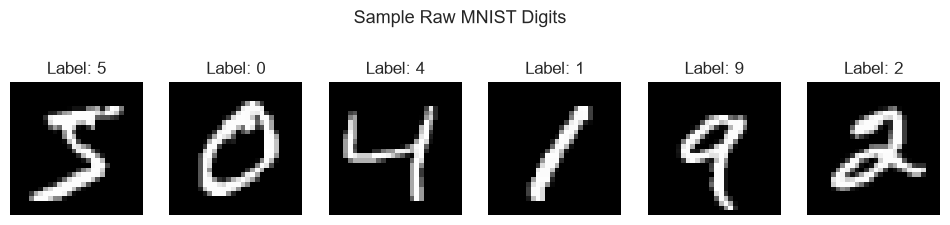

In [17]:
# 2. Loading Dataset
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

print(f"Training Images Shape: {x_train_raw.shape} -> (Samples, Height, Width)")
print(f"Training Labels Shape: {y_train.shape}")
print(f"Testing Images Shape:  {x_test_raw.shape}")
print(f"Testing Labels Shape:  {y_test.shape}")
print(f"Pixel Value Range:     Min={x_train_raw.min()}, Max={x_train_raw.max()}")

# Inspect 6 random sample digits
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for idx in range(6):
    axes[idx].imshow(x_train_raw[idx], cmap="gray")
    axes[idx].set_title(f"Label: {y_train[idx]}")
    axes[idx].axis("off")
plt.suptitle("Sample Raw MNIST Digits", y=1.05)
plt.show()


### Step 3: Preprocessing & Scaling

> 💡 *Beginner Tip:* Neural networks train much faster when input features are scaled to $[0.0, 1.0]$ rather than $[0, 255]$. Dividing by $255.0$ prevents large initial activations that saturate sigmoid/softmax functions.

**What this step does:**
1. Casts pixel values from integer `uint8` to floating-point `float32`.
2. Normalizes pixel values from $[0, 255]$ into $[0.0, 1.0]$:
   $$x_{\text{scaled}} = \frac{x}{255.0}$$
3. Preserves integer class targets ($0-9$) for compatibility with `SparseCategoricalCrossentropy`.


In [18]:
# 3. Preprocessing: Normalization
x_train = x_train_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

print(f"Preprocessed Training Range: Min={x_train.min():.2f}, Max={x_train.max():.2f}")
print(f"Preprocessed Data Type:      {x_train.dtype}")


Preprocessed Training Range: Min=0.00, Max=1.00
Preprocessed Data Type:      float32


### Step 4: Model Architecture Definition

> 💡 *Beginner Tip:* In Keras, `Sequential` allows you to assemble neural network layers like building blocks. You don't need to manually define forward math equations — Keras connects layers automatically!

**Key Keras Architectural Elements Explained:**
- `keras.Sequential([...])`: Linear container where each layer feeds directly into the next.
- `layers.Flatten(input_shape=(28, 28))`: Reshapes each 2D image into a flat 784-element vector. The `input_shape` argument on the first layer allows Keras to pre-allocate weight matrices immediately.
- `layers.Dense(128, activation='sigmoid')`: Fully connected hidden layer with 128 neurons. Applies linear transform followed by sigmoid activation $\sigma(z) = \frac{1}{1 + e^{-z}}$.
- `layers.Dense(10, activation='softmax')`: Output layer with 10 neurons. The softmax activation converts raw outputs into a normalized probability distribution where $\sum p_k = 1.0$.
- `model.summary()`: Displays an organized table of layer names, output shapes, and exact parameter counts.


In [19]:
# 4. Model Architecture: Single Hidden Layer Perceptron
model_single = keras.Sequential([
    # Input flattening: (28, 28) -> (784,)
    layers.Flatten(input_shape=(28, 28), name="flatten_input"),
    # Hidden Layer: 128 neurons with Sigmoid activation
    layers.Dense(128, activation='sigmoid', name="hidden_layer_1"),
    # Output Layer: 10 neurons with Softmax probability distribution
    layers.Dense(10, activation='softmax', name="output_classification")
], name="Single_Layer_Perceptron")

# Display architectural table
model_single.summary()


Model: "Single_Layer_Perceptron"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_input (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_1 (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classification (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Compilation & Training (Fit)

> 💡 *Beginner Tip:* Unlike PyTorch where you write training loops by hand, Keras packages training configuration into `model.compile()` and execution into `model.fit()`.

**Key Keras Functions Explained:**
- `model.compile(optimizer, loss, metrics)`: Configures learning mechanics:
  - `optimizer=optimizers.SGD(learning_rate=0.1, momentum=0.9)`: Momentum-accelerated stochastic gradient descent.
  - `loss=losses.SparseCategoricalCrossentropy()`: Computes cross-entropy loss directly from integer targets without requiring one-hot encoding.
  - `metrics=['accuracy']`: Tracks classification accuracy during training and validation.
- `model.fit(x, y, epochs=5, batch_size=64, validation_split=0.1)`: Executes the optimization loop:
  - `epochs=5`: Number of full passes over the 60,000 training images.
  - `batch_size=64`: Updates weights after every 64 images.
  - `validation_split=0.1`: Holds out 10% (6,000 images) to monitor generalization performance after each epoch.
  - Returns a `History` object containing loss and metric curves.


In [20]:
# 5. Fit: Model Compilation & Training
model_single.compile(
    optimizer=optimizers.SGD(learning_rate=0.1, momentum=0.9),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs_single = 5
batch_size_single = 64

print("Training Single-Layer Perceptron on MNIST...")
history_single = model_single.fit(
    x_train, y_train,
    epochs=epochs_single,
    batch_size=batch_size_single,
    validation_split=0.1,
    verbose=1
)
print("Training Complete!")


Training Single-Layer Perceptron on MNIST...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8898 - loss: 0.3654 - val_accuracy: 0.9537 - val_loss: 0.1698
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9466 - loss: 0.1797 - val_accuracy: 0.9665 - val_loss: 0.1220
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9608 - loss: 0.1295 - val_accuracy: 0.9715 - val_loss: 0.0972
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9698 - loss: 0.1001 - val_accuracy: 0.9738 - val_loss: 0.0937
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9757 - loss: 0.0821 - val_accuracy: 0.9780 - val_loss: 0.0801
Training Complete!


### Step 6: Predict (Inference on Test Set)

> 💡 *Beginner Tip:* `model.predict()` evaluates the entire test set in parallel batches. Because the final layer uses Softmax, each prediction is a vector of 10 probabilities. Use `np.argmax(axis=1)` to find the winning digit class!

**Key Functions Explained:**
- `model.predict(x_test)`: Generates a NumPy array of shape `(10000, 10)` containing class probabilities.
- `np.argmax(y_pred_probs, axis=1)`: Finds the index of the highest probability for each sample, giving the predicted digit ($0-9$).


In [21]:
# 6. Predict: Model Inference on Test Set
y_pred_probs_single = model_single.predict(x_test, batch_size=1000, verbose=0)
y_pred_single = np.argmax(y_pred_probs_single, axis=1)

print(f"Generated predictions for {len(y_pred_single):,} test images.")
print("Sample Softmax Probabilities for Image 0:\n", y_pred_probs_single[0].round(4))
print(f"Predicted Class for Image 0: {y_pred_single[0]} (True Label: {y_test[0]})")
print("First 10 Predicted Labels:", y_pred_single[:10])
print("First 10 Actual Labels:   ", y_test[:10])


Generated predictions for 10,000 test images.
Sample Softmax Probabilities for Image 0:
 [0.000e+00 0.000e+00 0.000e+00 1.000e-04 0.000e+00 0.000e+00 0.000e+00
 9.999e-01 0.000e+00 0.000e+00]
Predicted Class for Image 0: 7 (True Label: 7)
First 10 Predicted Labels: [7 2 1 0 4 1 4 9 6 9]
First 10 Actual Labels:    [7 2 1 0 4 1 4 9 5 9]


### Step 7: Evaluation

> 💡 *Beginner Tip:* `model.evaluate()` computes final test loss and accuracy on unseen test data. We also generate a full `classification_report` and `confusion_matrix` to inspect per-digit performance.

**Evaluation Metrics Explained:**
- **Test Loss:** Scalar categorical cross-entropy error on unseen test images.
- **Accuracy:** Overall percentage of correctly classified digits.
- **Precision & Recall:** Per-digit accuracy metrics measuring false positives and false negatives.


In [22]:
# 7. Evaluation: Performance Metrics
test_loss_single, test_acc_single = model_single.evaluate(x_test, y_test, verbose=0)

print("=" * 60)
print("SINGLE-LAYER PERCEPTRON EVALUATION REPORT (MNIST)")
print("=" * 60)
print(f"Test Cross-Entropy Loss: {test_loss_single:.4f}")
print(f"Overall Test Accuracy:   {test_acc_single * 100:.2f}%")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred_single, digits=4))


SINGLE-LAYER PERCEPTRON EVALUATION REPORT (MNIST)
Test Cross-Entropy Loss: 0.0899
Overall Test Accuracy:   97.34%
Detailed Classification Report:
              precision    recall  f1-score   support

           0     0.9797    0.9837    0.9817       980
           1     0.9774    0.9921    0.9847      1135
           2     0.9737    0.9700    0.9718      1032
           3     0.9648    0.9772    0.9710      1010
           4     0.9698    0.9807    0.9752       982
           5     0.9676    0.9697    0.9686       892
           6     0.9720    0.9770    0.9745       958
           7     0.9625    0.9747    0.9686      1028
           8     0.9772    0.9671    0.9721       974
           9     0.9896    0.9395    0.9639      1009

    accuracy                         0.9734     10000
   macro avg     0.9734    0.9732    0.9732     10000
weighted avg     0.9735    0.9734    0.9734     10000



### Step 8: Visualization

> 💡 *Beginner Tip:* The `history` object returned by `model.fit()` contains training and validation loss/accuracy across all epochs. Plotting these reveals convergence speed and overfitting patterns.


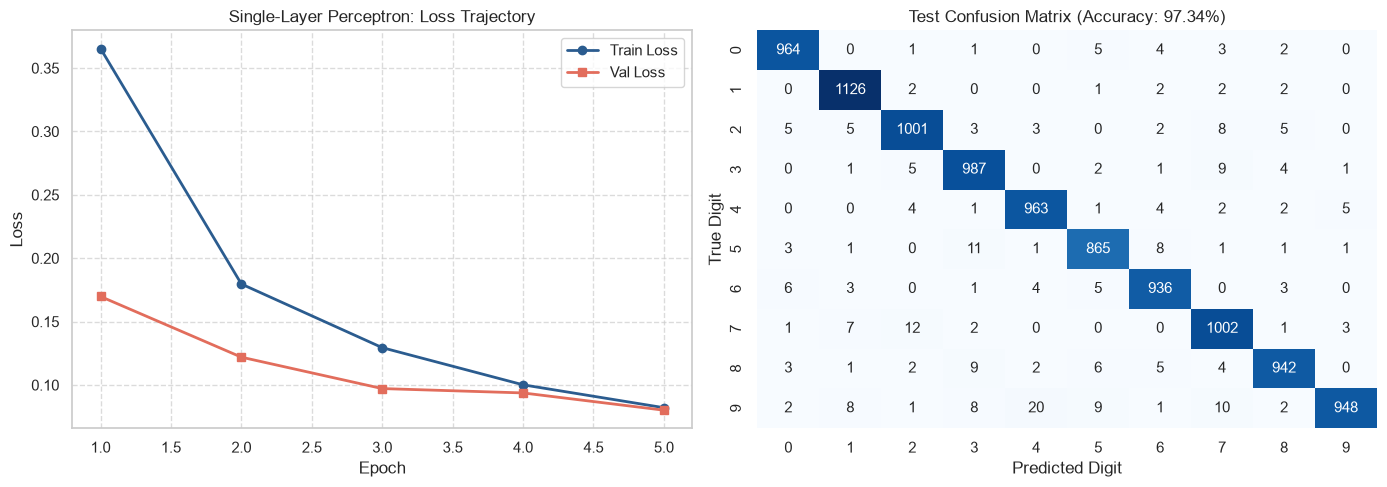

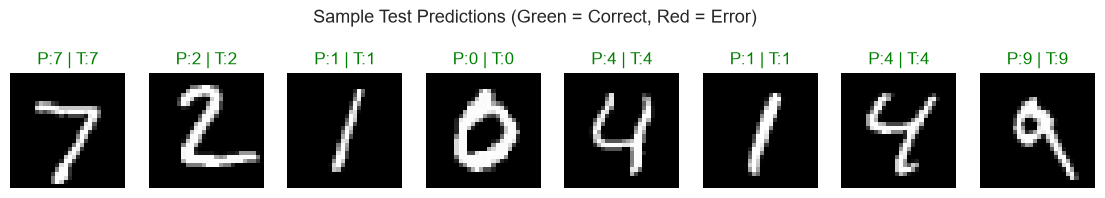

In [23]:
# 8. Visualization: Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training & Validation Loss
axes[0].plot(range(1, epochs_single + 1), history_single.history['loss'], marker='o', label="Train Loss", color='#2b5c8f', lw=2)
axes[0].plot(range(1, epochs_single + 1), history_single.history['val_loss'], marker='s', label="Val Loss", color='#e26d5c', lw=2)
axes[0].set_title("Single-Layer Perceptron: Loss Trajectory")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.7)

# Plot 2: Confusion Matrix Heatmap
cm_single = confusion_matrix(y_test, y_pred_single)
sns.heatmap(cm_single, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title(f"Test Confusion Matrix (Accuracy: {test_acc_single*100:.2f}%)")
axes[1].set_xlabel("Predicted Digit")
axes[1].set_ylabel("True Digit")

plt.tight_layout()
plt.show()

# Sample visual test predictions
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for idx in range(8):
    axes[idx].imshow(x_test[idx], cmap="gray")
    is_correct = y_pred_single[idx] == y_test[idx]
    col = "green" if is_correct else "red"
    axes[idx].set_title(f"P:{y_pred_single[idx]} | T:{y_test[idx]}", color=col)
    axes[idx].axis("off")
plt.suptitle("Sample Test Predictions (Green = Correct, Red = Error)", y=1.1)
plt.show()


---
## 1.2 Deep Multi-Layer Perceptron (MLP) with ReLU & Dropout

A single hidden layer can struggle to model complex non-linear feature interactions. We now build a **Deep Multi-Layer Perceptron** in Keras featuring:
- **3 Hidden Layers:** $[784 \to 512 \to 256 \to 128 \to 10]$.
- **ReLU Activations:** Prevents vanishing gradients and accelerates convergence.
- **Dropout Regularization ($p=0.2$):** Prevents co-adaptation of neurons and reduces overfitting.
- **Adam Optimizer:** Adaptive moment estimation with momentum and per-parameter adaptive learning rates.

---

#### 🔬 Deep Layer Internals: Inside Dropout Regularization (`layers.Dropout`)
`layers.Dropout(rate=0.2)` randomly sets neuron activations to zero with probability $p=0.2$ during training:
$$\tilde{a}_i = \begin{cases} 0, & \text{with probability } p \\ \frac{a_i}{1 - p}, & \text{with probability } 1 - p \end{cases}$$
- **Inverted Scaling:** Scaling active neurons by $\frac{1}{1-p}$ ensures the expected sum of activations remains constant between training and inference:
  $$\mathbb{E}[\tilde{a}_i] = (1 - p) \cdot \frac{a_i}{1 - p} + p \cdot 0 = a_i$$
- **Automatic State Management:** Keras automatically disables Dropout during `model.predict()` and `model.evaluate()`. No neurons are dropped during inference!

---

#### 🔬 Deep Layer Internals: Inside the Adam Optimizer (`optimizers.Adam`)
Adam (Kingma & Ba, 2014) tracks exponentially decaying averages of past gradients ($m_t$) and squared gradients ($v_t$):
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \quad \text{(First Moment: Direction)}$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \quad \text{(Second Moment: Scale)}$$
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \quad \text{(Bias Correction)}$$
$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t \quad \text{(Parameter Update)}$$
Parameters with large, volatile gradients receive smaller updates, while parameters with infrequent gradients receive larger updates.


In [24]:
# 4. Model Architecture: Deep Multi-Layer Perceptron (MLP)
model_mlp = keras.Sequential([
    layers.Flatten(input_shape=(28, 28), name="flatten_input"),
    # Hidden Layer 1
    layers.Dense(512, activation='relu', name="dense_1"),
    layers.Dropout(0.2, name="dropout_1"),
    # Hidden Layer 2
    layers.Dense(256, activation='relu', name="dense_2"),
    layers.Dropout(0.2, name="dropout_2"),
    # Hidden Layer 3
    layers.Dense(128, activation='relu', name="dense_3"),
    layers.Dropout(0.2, name="dropout_3"),
    # Output Layer
    layers.Dense(10, activation='softmax', name="output_layer")
], name="Deep_MLP")

model_mlp.summary()


c:\Users\Ayush\Desktop\ACC-HPC2026-AIML\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "Deep_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_input (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# 5. Fit: Training Deep MLP with Adam Optimizer
model_mlp.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs_mlp = 5
print("Training Deep MLP with Adam Optimizer...")
history_mlp = model_mlp.fit(
    x_train, y_train,
    epochs=epochs_mlp,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)
print("Deep MLP Training Complete!")


Training Deep MLP with Adam Optimizer...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9144 - loss: 0.2808 - val_accuracy: 0.9667 - val_loss: 0.1131
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9639 - loss: 0.1242 - val_accuracy: 0.9788 - val_loss: 0.0697
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9715 - loss: 0.0941 - val_accuracy: 0.9782 - val_loss: 0.0709
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9772 - loss: 0.0751 - val_accuracy: 0.9795 - val_loss: 0.0814
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9799 - loss: 0.0648 - val_accuracy: 0.9795 - val_loss: 0.0741
Deep MLP Training Complete!


In [26]:
# 6 & 7. Predict & Evaluation: Deep MLP Performance vs Single-Layer Perceptron
test_loss_mlp, test_acc_mlp = model_mlp.evaluate(x_test, y_test, verbose=0)
y_pred_mlp = np.argmax(model_mlp.predict(x_test, batch_size=1000, verbose=0), axis=1)

print("=" * 60)
print("DEEP MLP vs SINGLE-LAYER PERCEPTRON COMPARISON (MNIST)")
print("=" * 60)
print(f"Single-Layer Perceptron Test Accuracy: {test_acc_single * 100:.2f}%")
print(f"Deep MLP (ReLU + Dropout) Accuracy:    {test_acc_mlp * 100:.2f}%")
print(f"Accuracy Gain:                         +{(test_acc_mlp - test_acc_single) * 100:.2f}%")
print("Deep MLP Classification Report:")
print(classification_report(y_test, y_pred_mlp, digits=4))


DEEP MLP vs SINGLE-LAYER PERCEPTRON COMPARISON (MNIST)
Single-Layer Perceptron Test Accuracy: 97.34%
Deep MLP (ReLU + Dropout) Accuracy:    97.91%
Accuracy Gain:                         +0.57%
Deep MLP Classification Report:
              precision    recall  f1-score   support

           0     0.9809    0.9949    0.9878       980
           1     0.9843    0.9956    0.9899      1135
           2     0.9806    0.9816    0.9811      1032
           3     0.9707    0.9832    0.9769      1010
           4     0.9785    0.9735    0.9760       982
           5     0.9930    0.9596    0.9761       892
           6     0.9772    0.9833    0.9802       958
           7     0.9814    0.9757    0.9785      1028
           8     0.9783    0.9713    0.9748       974
           9     0.9673    0.9683    0.9678      1009

    accuracy                         0.9791     10000
   macro avg     0.9792    0.9787    0.9789     10000
weighted avg     0.9791    0.9791    0.9791     10000



---
# 2. CNN — Convolutional Neural Networks

While MLPs perform well on flattened vectors, they discard 2D spatial context. A pixel is naturally correlated with its spatial neighbors. **Convolutional Neural Networks (CNNs)** preserve 2D grid structure using specialized spatial operations.

### Core CNN Principles:
1. **Local Receptive Fields:** Neurons connect only to a small local patch of the input (e.g., $3 \times 3$ pixels).
2. **Weight / Parameter Sharing:** The same filter (kernel) slides across the entire image. If an edge detector works in the top-left corner, it works equally well in the bottom-right corner!
3. **Translation Invariance:** Pooling layers ensure that whether an object shifts slightly left or right, the activation remains similar.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine inspecting a giant mural with a magnifying glass. You don't try to swallow the entire wall in one glance. You slide your small circular lens (the convolution filter) row by row. At each spot, your magnifying glass checks for tiny brushstrokes: vertical lines, curves, corners. Later layers combine those small brushstroke detections into larger shapes (eyes, wheels, ears), and the final layer determines whether the mural is a portrait or a landscape!

---

#### 🔬 Deep Layer Internals: Inside a 2D Convolutional Layer (`layers.Conv2D`)
In Keras, `layers.Conv2D(filters, kernel_size, strides=(1, 1), padding='valid', activation=None)`:

- **Mathematical Formula:** For filter $k$ at coordinate $(i, j)$:
  $$\text{Output}(i, j, k) = \mathbf{b}_k + \sum_{c=1}^{C_{in}} \sum_{m} \sum_{n} \mathbf{X}(i \cdot S + m, j \cdot S + n, c) \cdot \mathbf{W}(m, n, c, k)$$
- **Spatial Output Dimension Formula:**
  $$H_{out} = \left\lfloor \frac{H_{in} - K_h + 2P}{S} \right\rfloor + 1, \quad W_{out} = \left\lfloor \frac{W_{in} - K_w + 2P}{S} \right\rfloor + 1$$
- **Padding Options in Keras:**
  - `padding='valid'`: No padding ($P=0$). Output shrinks by $K - 1$.
  - `padding='same'`: Zeros added around border so $H_{out} = H_{in}$ when stride=1.
- **Parameter Count:**
  $$\text{Parameters} = \text{filters} \times (K_h \times K_w \times C_{in} + 1)$$
  A layer with $C_{in}=1$, filters$=32$, $K=(3,3)$ has:
  $$32 \times (3 \times 3 \times 1 + 1) = 32 \times 10 = 320 \text{ parameters!}$$

---

#### 🔬 Deep Layer Internals: Inside Max Pooling (`layers.MaxPooling2D`)
`layers.MaxPooling2D(pool_size=(2, 2))` downsamples spatial dimensions:
$$\text{Output}(i, j, k) = \max_{m \in [0, 1], n \in [0, 1]} \mathbf{X}(2i + m, 2j + n, k)$$
- **No Learnable Parameters:** Max pooling has 0 weights and 0 biases.
- **Dimensional Impact:** Halves both height and width ($28 \times 28 \to 14 \times 14$), discarding 75% of activations while retaining the strongest signal activations.


In [27]:
# 3 & 4. CNN Data Preparation & Architecture Definition
# CNNs expect 4D tensor inputs: (Batch, Height, Width, Channels)
x_train_cnn = np.expand_dims(x_train, -1)  # (60000, 28, 28, 1)
x_test_cnn = np.expand_dims(x_test, -1)    # (10000, 28, 28, 1)

print(f"Reshaped Input for CNN: {x_train_cnn.shape} -> (Batch, H, W, Channels)")

# Build CNN Architecture
model_cnn = keras.Sequential([
    # Block 1: Conv -> MaxPool
    layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', input_shape=(28, 28, 1), name="conv_1"),
    layers.MaxPooling2D(pool_size=(2, 2), name="maxpool_1"),
    # Block 2: Conv -> MaxPool
    layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name="conv_2"),
    layers.MaxPooling2D(pool_size=(2, 2), name="maxpool_2"),
    # Dense Classifier Head
    layers.Flatten(name="flatten"),
    layers.Dropout(0.25, name="dropout_cnn"),
    layers.Dense(128, activation='relu', name="dense_cnn"),
    layers.Dense(10, activation='softmax', name="output_cnn")
], name="Convolutional_Neural_Network")

model_cnn.summary()


Reshaped Input for CNN: (60000, 28, 28, 1) -> (Batch, H, W, Channels)


c:\Users\Ayush\Desktop\ACC-HPC2026-AIML\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Convolutional_Neural_Network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_cnn (Dropout)           │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_cnn (Dense)               │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_cnn (Dense)              │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# 5. Fit: Training the CNN
model_cnn.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs_cnn = 5
print("Training CNN on MNIST with GPU acceleration...")
history_cnn = model_cnn.fit(
    x_train_cnn, y_train,
    epochs=epochs_cnn,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)
print("CNN Training Complete!")


Training CNN on MNIST with GPU acceleration...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9447 - loss: 0.1798 - val_accuracy: 0.9875 - val_loss: 0.0462
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9839 - loss: 0.0525 - val_accuracy: 0.9885 - val_loss: 0.0392
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9877 - loss: 0.0392 - val_accuracy: 0.9892 - val_loss: 0.0366
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9901 - loss: 0.0301 - val_accuracy: 0.9913 - val_loss: 0.0303
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9918 - loss: 0.0251 - val_accuracy: 0.9882 - val_loss: 0.0363
CNN Training Complete!


In [29]:
# 6 & 7. Predict & Evaluation: CNN Performance
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(x_test_cnn, y_test, verbose=0)
y_pred_cnn = np.argmax(model_cnn.predict(x_test_cnn, batch_size=1000, verbose=0), axis=1)

print("=" * 60)
print("CNN EVALUATION REPORT (MNIST)")
print("=" * 60)
print(f"CNN Test Accuracy:                     {test_acc_cnn * 100:.2f}%")
print(f"Comparison with Deep MLP Accuracy:     {test_acc_mlp * 100:.2f}%")
print(f"Performance Advantage of Conv Layers:  +{(test_acc_cnn - test_acc_mlp) * 100:.2f}%")
print(classification_report(y_test, y_pred_cnn, digits=4))


CNN EVALUATION REPORT (MNIST)
CNN Test Accuracy:                     98.99%
Comparison with Deep MLP Accuracy:     97.91%
Performance Advantage of Conv Layers:  +1.08%
              precision    recall  f1-score   support

           0     0.9674    0.9990    0.9829       980
           1     0.9921    0.9965    0.9943      1135
           2     0.9894    0.9922    0.9908      1032
           3     0.9921    0.9970    0.9946      1010
           4     0.9909    0.9959    0.9934       982
           5     0.9877    0.9933    0.9905       892
           6     0.9989    0.9718    0.9852       958
           7     0.9990    0.9767    0.9877      1028
           8     0.9948    0.9877    0.9912       974
           9     0.9871    0.9881    0.9876      1009

    accuracy                         0.9899     10000
   macro avg     0.9899    0.9898    0.9898     10000
weighted avg     0.9900    0.9899    0.9899     10000



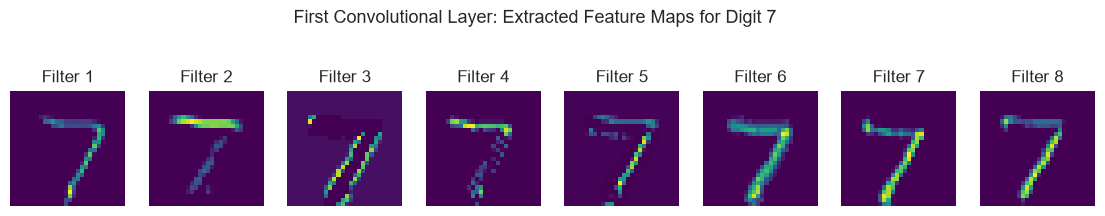

In [30]:
# 8. Visualization: CNN Feature Maps & Learned Activations
# In Keras, we extract intermediate activations using a Functional sub-model
conv1_extractor = keras.Model(inputs=model_cnn.inputs, outputs=model_cnn.get_layer("conv_1").output)
sample_digit = np.expand_dims(x_test_cnn[0], 0)  # Digit 7

conv1_activations = conv1_extractor.predict(sample_digit, verbose=0)[0]  # (28, 28, 32)

fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i in range(8):
    axes[i].imshow(conv1_activations[:, :, i], cmap="viridis")
    axes[i].set_title(f"Filter {i+1}")
    axes[i].axis("off")
plt.suptitle("First Convolutional Layer: Extracted Feature Maps for Digit 7", y=1.05)
plt.show()


---
# 3. RNN — Recurrent Neural Networks

Standard feedforward networks and CNNs assume all input vectors are statistically independent. However, real-world sequential data — such as natural language text, speech, audio, and financial time-series — depends fundamentally on **sequential ordering**.

A **Recurrent Neural Network (RNN)** processes sequences step-by-step, maintaining an internal **hidden state** $\mathbf{h}_t$ that acts as memory of past steps.

---

#### 🔬 Deep Layer Internals: Inside an Embedding Layer (`layers.Embedding`)
In Keras, `layers.Embedding(input_dim, output_dim, input_length=None)` creates a learnable lookup matrix $\mathbf{E} \in \mathbb{R}^{V \times D}$:
- **Lookup Operation:** Given an integer word ID $w_t \in \{0, 1, \dots, V-1\}$, the layer retrieves row $w_t$ of matrix $\mathbf{E}$:
  $$\mathbf{x}_t = \mathbf{E}[w_t, :] \in \mathbb{R}^D$$
- **Semantic Vector Geometry:** Through backpropagation, words appearing in similar contexts (e.g., *"excellent"* and *"wonderful"*) gravitate toward each other in embedding space.
- **Parameter Count:** $\text{Parameters} = V 	imes D$ (e.g., $10{,}000 \times 32 = 320{,}000$).

---

#### 🔬 Deep Layer Internals: Inside a Vanilla RNN Cell (`layers.SimpleRNN`)
At each discrete timestep $t$ in a sequence of length $T$:
$$\mathbf{h}_t = \tanh(\mathbf{W}_{ih} \mathbf{x}_t + \mathbf{W}_{hh} \mathbf{h}_{t-1} + \mathbf{b}_h)$$
- $\mathbf{x}_t \in \mathbb{R}^{D}$: Current word embedding.
- $\mathbf{h}_{t-1} \in \mathbb{R}^{H}$: Hidden state from previous timestep.
- $\mathbf{W}_{hh} \in \mathbb{R}^{H \times H}$: Recurrent transition weights shared across all timesteps.
- `return_sequences=False`: Keras outputs only the final hidden state $\mathbf{h}_T$ (useful for classification). Setting `return_sequences=True` outputs all hidden states $[\mathbf{h}_1, \dots, \mathbf{h}_T]$ (useful for seq2seq tasks).

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine reading a suspense mystery novel. As you read word by word, you don't memorize every single past letter. Instead, you keep a running mental summary in your head: *"The detective just found a footprint in the mud."* When you read the next word, you update your mental summary. The **hidden state** is that running mental summary!

---

#### The Fundamental Flaw of Vanilla RNNs: Vanishing & Exploding Gradients
During Backpropagation Through Time (BPTT), the gradient of loss with respect to early hidden state $\mathbf{h}_1$ involves a chain of matrix multiplications by $\mathbf{W}_{hh}^T$:
$$\frac{\partial \mathcal{L}}{\partial \mathbf{h}_1} = \frac{\partial \mathcal{L}}{\partial \mathbf{h}_T} \prod_{k=2}^{T} \frac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}} = \frac{\partial \mathcal{L}}{\partial \mathbf{h}_T} \prod_{k=2}^{T} \mathbf{W}_{hh}^T \text{diag}(1 - \tanh^2(\cdot))$$
- If the eigenvalues of $\mathbf{W}_{hh}$ are $< 1$, the gradient shrinks exponentially toward zero as $T$ increases. The network completely "forgets" words read 10 steps ago!
- If the eigenvalues are $> 1$, gradients explode to `NaN` or infinity.


In [31]:
# 2 & 3. Synthetic Sentiment Classification Dataset Pipeline
vocabulary = {
    "<PAD>": 0, "<UNK>": 1, "great": 2, "excellent": 3, "superb": 4, "love": 5,
    "brilliant": 6, "masterpiece": 7, "fantastic": 8, "wonderful": 9, "bad": 10,
    "terrible": 11, "awful": 12, "worst": 13, "horrible": 14, "boring": 15,
    "waste": 16, "poor": 17, "acting": 18, "movie": 19, "film": 20, "plot": 21,
    "story": 22, "director": 23, "recommend": 24, "avoid": 25, "enjoyed": 26
}
vocab_size = len(vocabulary)

pos_phrases = [
    "great movie superb acting love it", "excellent film wonderful story brilliant",
    "fantastic director masterpiece love", "enjoyed movie great plot brilliant",
    "superb acting fantastic story recommend", "wonderful movie excellent acting love",
    "great film brilliant director recommend", "masterpiece film superb plot enjoyed"
]
neg_phrases = [
    "terrible movie awful acting waste", "bad film horrible plot boring",
    "worst movie terrible director avoid", "awful story bad acting waste",
    "boring movie horrible plot avoid", "poor film terrible acting worst",
    "bad movie boring story avoid", "horrible film waste of time poor"
]

def encode_and_pad(sentence, max_len=10):
    tokens = [vocabulary.get(word, vocabulary["<UNK>"]) for word in sentence.split()]
    if len(tokens) < max_len:
        tokens = tokens + [vocabulary["<PAD>"]] * (max_len - len(tokens))
    else:
        tokens = tokens[:max_len]
    return tokens

np.random.seed(42)
num_samples_per_class = 600

X_data, y_data = [], []
for _ in range(num_samples_per_class):
    pos_sent = np.random.choice(pos_phrases)
    neg_sent = np.random.choice(neg_phrases)
    X_data.append(encode_and_pad(pos_sent))
    y_data.append(1)  # Positive
    X_data.append(encode_and_pad(neg_sent))
    y_data.append(0)  # Negative

X_seq = np.array(X_data, dtype="int32")
y_seq = np.array(y_data, dtype="int32")

# Train/Test Split (80% / 20%)
split_idx = int(0.8 * len(X_seq))
X_train_seq, X_test_seq = X_seq[:split_idx], X_seq[split_idx:]
y_train_seq, y_test_seq = y_seq[:split_idx], y_seq[split_idx:]

print(f"Sequential Training Samples: {len(X_train_seq)}, Testing Samples: {len(X_test_seq)}")


Sequential Training Samples: 960, Testing Samples: 240


In [32]:
# 4. Model Architecture: Vanilla Recurrent Neural Network (SimpleRNN)
model_rnn = keras.Sequential([
    # Embedding layer maps word IDs to 32D dense vectors
    layers.Embedding(input_dim=vocab_size, output_dim=32, input_length=10, name="embedding"),
    # Vanilla SimpleRNN layer
    layers.SimpleRNN(64, return_sequences=False, name="simplernn_layer"),
    # Binary Classification Output
    layers.Dense(2, activation='softmax', name="output_sentiment")
], name="Vanilla_RNN")

model_rnn.summary()


c:\Users\Ayush\Desktop\ACC-HPC2026-AIML\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "Vanilla_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simplernn_layer (SimpleRNN)     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_sentiment (Dense)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [33]:
# 5. Fit & Evaluate Vanilla RNN
model_rnn.compile(
    optimizer=optimizers.Adam(learning_rate=0.005),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs_seq = 6
history_rnn = model_rnn.fit(
    X_train_seq, y_train_seq,
    epochs=epochs_seq,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

test_loss_rnn, test_acc_rnn = model_rnn.evaluate(X_test_seq, y_test_seq, verbose=0)
print(f"\nVanilla RNN Test Accuracy: {test_acc_rnn * 100:.2f}%")


Epoch 1/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9699 - loss: 0.0738 - val_accuracy: 1.0000 - val_loss: 7.9530e-05
Epoch 2/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 3.6565e-05 - val_accuracy: 1.0000 - val_loss: 1.8341e-05
Epoch 3/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 1.5878e-05 - val_accuracy: 1.0000 - val_loss: 1.3158e-05
Epoch 4/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 1.2177e-05 - val_accuracy: 1.0000 - val_loss: 1.0550e-05
Epoch 5/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 9.9462e-06 - val_accuracy: 1.0000 - val_loss: 8.7432e-06
Epoch 6/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 8.3332e-06 - val_accuracy: 1.0000 - val_loss: 7.3996e-06

Vanilla RNN Test Accuracy: 100.00%


---
# 4. LSTM — Long Short-Term Memory Networks

To overcome the vanishing gradient limitation of standard RNNs, Hochreiter & Schmidhuber (1997) introduced the **Long Short-Term Memory (LSTM)** architecture.

LSTMs introduce a dedicated internal **Cell State** ($\mathbf{C}_t$) that runs straight down the sequence with only linear interactions, protected by three learnable non-linear regulatory **Gates**.

---

#### 🔬 Deep Layer Internals: The Four Mathematical Mechanisms of an LSTM Cell (`layers.LSTM`)
At each timestep $t$, an LSTM computes:

1. **Forget Gate ($\mathbf{f}_t$):** Decides what information to erase from the cell state.
   $$\mathbf{f}_t = \sigma(\mathbf{W}_f \mathbf{x}_t + \mathbf{U}_f \mathbf{h}_{t-1} + \mathbf{b}_f) \in [0, 1]$$
   - Output of $0$ means *"completely forget this past information"*.
   - Output of $1$ means *"completely preserve this past information"*.
2. **Input Gate ($\mathbf{i}_t$):** Decides which new candidate values to record.
   $$\mathbf{i}_t = \sigma(\mathbf{W}_i \mathbf{x}_t + \mathbf{U}_i \mathbf{h}_{t-1} + \mathbf{b}_i) \in [0, 1]$$
   $$\tilde{\mathbf{C}}_t = \tanh(\mathbf{W}_c \mathbf{x}_t + \mathbf{U}_c \mathbf{h}_{t-1} + \mathbf{b}_c) \in [-1, 1]$$
3. **Cell State Update ($\mathbf{C}_t$):** The linear highway update:
   $$\mathbf{C}_t = \mathbf{f}_t \odot \mathbf{C}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{C}}_t$$
   *Notice the addition ($+$)! Because updates are additive rather than purely multiplicative, error gradients can flow backward through time across hundreds of steps without vanishing!*
4. **Output Gate ($\mathbf{o}_t$) & Hidden State ($\mathbf{h}_t$):**
   $$\mathbf{o}_t = \sigma(\mathbf{W}_o \mathbf{x}_t + \mathbf{U}_o \mathbf{h}_{t-1} + \mathbf{b}_o)$$
   $$\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{C}_t)$$

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Think of an LSTM as a student studying for a history exam with a digital notebook.
> - The **Forget Gate** is the backspace key: it deletes outdated information (like a rumor that turned out to be false).
> - The **Input Gate** is the copy-paste tool: when the teacher says *"This will definitely be on the exam,"* it saves those key facts into the notebook.
> - The **Cell State** is the notebook itself — safely carrying important memories across all chapters.
> - The **Output Gate** is the student answering a specific quiz question based on what's currently in their notes.


In [34]:
# 4. Model Architecture: Bidirectional Long Short-Term Memory (LSTM)
model_lstm = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=32, input_length=10, name="embedding"),
    # Bidirectional wrapper runs an LSTM forward and backward, concatenating both outputs
    layers.Bidirectional(layers.LSTM(64, return_sequences=False), name="bidirectional_lstm"),
    layers.Dropout(0.3, name="dropout"),
    layers.Dense(2, activation='softmax', name="output_sentiment")
], name="Bidirectional_LSTM")

model_lstm.summary()


Model: "Bidirectional_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm              │ ?                      │   0 (unbuilt) │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_sentiment (Dense)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [36]:
# 5, 6 & 7. Fit & Comparative Evaluation: LSTM vs Vanilla RNN
model_lstm.compile(
    optimizer=optimizers.Adam(learning_rate=0.005),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

history_lstm = model_lstm.fit(
    X_train_seq, y_train_seq,
    epochs=epochs_seq,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

test_loss_lstm, test_acc_lstm = model_lstm.evaluate(X_test_seq, y_test_seq, verbose=0)
y_pred_lstm = np.argmax(model_lstm.predict(X_test_seq, verbose=0), axis=1)

print("=" * 60)
print("SEQUENCE MODEL COMPARISON: RNN vs LSTM")
print("=" * 60)
print(f"Vanilla SimpleRNN Test Accuracy: {test_acc_rnn * 100:.2f}%")
print(f"Bidirectional LSTM Accuracy:    {test_acc_lstm * 100:.2f}%")
print(f"Gating Advantage:               +{(test_acc_lstm - test_acc_rnn) * 100:.2f}%")
print(classification_report(y_test_seq, y_pred_lstm, target_names=["Negative", "Positive"]))


Epoch 1/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9248 - loss: 0.1872 - val_accuracy: 1.0000 - val_loss: 1.1727e-05
Epoch 2/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 7.4455e-06 - val_accuracy: 1.0000 - val_loss: 2.6921e-06
Epoch 3/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 3.3774e-06 - val_accuracy: 1.0000 - val_loss: 1.7596e-06
Epoch 4/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 2.7803e-06 - val_accuracy: 1.0000 - val_loss: 1.2616e-06
Epoch 5/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.8386e-06 - val_accuracy: 1.0000 - val_loss: 1.0021e-06
Epoch 6/6
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.4894e-06 - val_accuracy: 1.0000 - val_loss: 8.0218e-07
SEQUENCE MODEL COMPARISON: RNN vs LSTM
Vanilla SimpleRNN Test Accuracy: 100.00%
Bidirectional LSTM Accuracy:    100.00%
Gating Advantage:               +0.00%
              precision    recall  f1-score   

---
# 5. Practical Application: End-to-End Deep Pipeline (CIFAR-10)

We now implement an industry-grade deep vision pipeline on the **CIFAR-10** benchmark dataset (60,000 $32 \times 32$ RGB color images across 10 diverse classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

### Real-World Production Techniques Included:
1. **Data Augmentation (`layers.RandomFlip`, `layers.RandomCrop`, `layers.RandomRotation`):** Native in-graph image augmentation to prevent memorization and overfitting.
2. **Batch Normalization (`layers.BatchNormalization`):** Stabilizes internal covariate shift and accelerates convergence.
3. **Learning Rate Scheduling (`callbacks.ReduceLROnPlateau`):** Automatically decays the learning rate when validation loss plateaus.
4. **Model Checkpointing (`callbacks.ModelCheckpoint`):** Saves the model weights with best validation accuracy automatically to disk.

---

#### 🔬 Deep Layer Internals: Inside Batch Normalization (`layers.BatchNormalization`)
Ioffe & Szegedy (2015) introduced Batch Normalization to solve internal covariate shift:
- **Mini-Batch Statistics:** For channel $c$:
  $$\mu_B = \frac{1}{m} \sum_{i=1}^{m} x_i, \quad \sigma_B^2 = \frac{1}{m} \sum_{i=1}^{m} (x_i - \mu_B)^2$$
- **Normalization:**
  $$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$
- **Scale and Shift:** Re-introduces representational capacity via two learnable parameters per channel ($\gamma$ and $\beta$):
  $$y_i = \gamma \hat{x}_i + \beta$$
- **Inference Mode:** During inference, BatchNormalization uses running averages of $\mu$ and $\sigma^2$ gathered during training, ensuring deterministic inference for single images.


In [39]:
# 1, 2 & 3. CIFAR-10 Dataset & Subsampling
cifar_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

(x_train_cifar_full, y_train_cifar_full), (x_test_cifar_full, y_test_cifar_full) = keras.datasets.cifar10.load_data()

# Normalize RGB pixel intensities to [0.0, 1.0]
x_train_cifar_full = x_train_cifar_full.astype("float32") / 255.0
x_test_cifar_full = x_test_cifar_full.astype("float32") / 255.0

# Subsample a fast representative partition for responsive instructional execution
np.random.seed(42)
train_indices = np.random.choice(len(x_train_cifar_full), 10000, replace=False)
test_indices = np.random.choice(len(x_test_cifar_full), 2000, replace=False)

x_train_cifar, y_train_cifar = x_train_cifar_full[train_indices], y_train_cifar_full[train_indices]
x_test_cifar, y_test_cifar = x_test_cifar_full[test_indices], y_test_cifar_full[test_indices]

print(f"CIFAR-10 Subsampled Training Samples: {len(x_train_cifar)}")
print(f"CIFAR-10 Subsampled Testing Samples:  {len(x_test_cifar)}")
print(f"Image Tensor Shape: {x_train_cifar.shape[1:]} -> (Height, Width, Color Channels)")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 5036s 30us/step
CIFAR-10 Subsampled Training Samples: 10000
CIFAR-10 Subsampled Testing Samples:  2000
Image Tensor Shape: (32, 32, 3) -> (Height, Width, Color Channels)


In [40]:
# 4. Model Architecture: Deep CNN with In-Graph Augmentation & Batch Normalization
model_cifar = keras.Sequential([
    # In-Graph Data Augmentation Layers
    layers.RandomFlip("horizontal", input_shape=(32, 32, 3), name="data_aug_flip"),
    layers.RandomRotation(0.1, name="data_aug_rotation"),

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same', name="conv1_1"),
    layers.BatchNormalization(name="bn1_1"),
    layers.Activation("relu"),
    layers.Conv2D(64, (3, 3), padding='same', name="conv1_2"),
    layers.BatchNormalization(name="bn1_2"),
    layers.Activation("relu"),
    layers.MaxPooling2D(pool_size=(2, 2), name="pool1"),
    layers.Dropout(0.25, name="drop1"),

    # Conv Block 2
    layers.Conv2D(128, (3, 3), padding='same', name="conv2_1"),
    layers.BatchNormalization(name="bn2_1"),
    layers.Activation("relu"),
    layers.MaxPooling2D(pool_size=(2, 2), name="pool2"),
    layers.Dropout(0.3, name="drop2"),

    # Dense Classification Head
    layers.Flatten(name="flatten"),
    layers.Dense(256, name="dense_feat"),
    layers.BatchNormalization(name="bn_dense"),
    layers.Activation("relu"),
    layers.Dropout(0.4, name="drop3"),
    layers.Dense(10, activation='softmax', name="output_cifar")
], name="CIFAR10_Deep_Classifier")

model_cifar.summary()


c:\Users\Ayush\Desktop\ACC-HPC2026-AIML\.venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "CIFAR10_Deep_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_aug_flip (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_aug_rotation               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_feat (Dense)              │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_dense (BatchNormalization)   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_cifar (Dense)            │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,195,146 (8.37 MB)

 Trainable params: 2,194,186 (8.37 MB)

 Non-trainable params: 960 (3.75 KB)

In [41]:
# 5. Fit: Training with Learning Rate Reduction & Checkpoint Callbacks
checkpoint_filepath = "best_cifar_tf_model.keras"

model_callbacks = [
    # Reduce learning rate when validation loss plateaus
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    # Automatically save only the best model weights
    callbacks.ModelCheckpoint(filepath=checkpoint_filepath, monitor='val_accuracy', save_best_only=True, verbose=1),
    # Early stopping if model fails to improve
    callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
]

model_cifar.compile(
    optimizer=optimizers.Adam(learning_rate=0.003),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs_cifar = 4
print("Training CIFAR-10 Model with Automated Keras Callbacks...")
history_cifar = model_cifar.fit(
    x_train_cifar, y_train_cifar,
    epochs=epochs_cifar,
    batch_size=64,
    validation_data=(x_test_cifar, y_test_cifar),
    callbacks=model_callbacks,
    verbose=1
)
print("CIFAR-10 Training Complete!")


Training CIFAR-10 Model with Automated Keras Callbacks...
Epoch 1/4
156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.3670 - loss: 1.8080
Epoch 1: val_accuracy improved from None to 0.16100, saving model to best_cifar_tf_model.keras

Epoch 1: finished saving model to best_cifar_tf_model.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 15s 86ms/step - accuracy: 0.3671 - loss: 1.8075 - val_accuracy: 0.1610 - val_loss: 2.8227 - learning_rate: 0.0030
Epoch 2/4
156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.4628 - loss: 1.4713
Epoch 2: val_accuracy improved from 0.16100 to 0.29850, saving model to best_cifar_tf_model.keras

Epoch 2: finished saving model to best_cifar_tf_model.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.4625 - loss: 1.4716 - val_accuracy: 0.2985 - val_loss: 2.2945 - learning_rate: 0.0030
Epoch 3/4
156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.5287 - loss: 1.3382
Epoch 3: val_accuracy improved from 0.29850 to 0.51650, saving model to best_cifar_

CIFAR-10 FINAL EVALUATION REPORT
Optimal Checkpoint Test Accuracy: 51.65%
              precision    recall  f1-score   support

    airplane     0.5100    0.6865    0.5853       185
  automobile     0.7801    0.5473    0.6433       201
        bird     0.4028    0.3953    0.3991       215
         cat     0.3782    0.2261    0.2830       199
        deer     0.6129    0.1854    0.2846       205
         dog     0.3654    0.6717    0.4733       198
        frog     0.9103    0.3622    0.5182       196
       horse     0.5394    0.6884    0.6049       199
        ship     0.6751    0.6683    0.6717       199
       truck     0.4738    0.7586    0.5833       203

    accuracy                         0.5165      2000
   macro avg     0.5648    0.5190    0.5047      2000
weighted avg     0.5637    0.5165    0.5029      2000



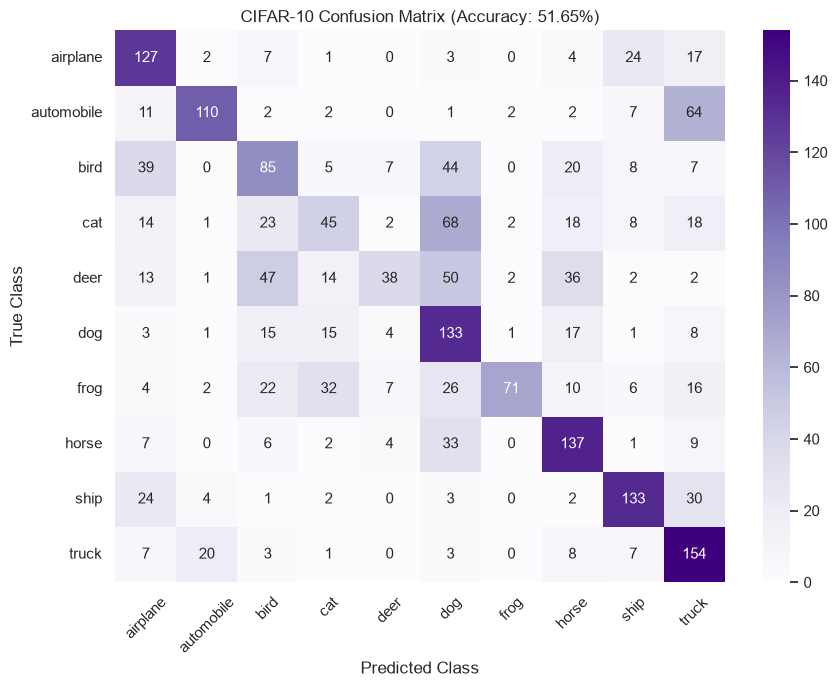

In [42]:
# 6, 7 & 8. Predict, Evaluation & Visualization
# Evaluate on test set
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(x_test_cifar, y_test_cifar, verbose=0)
y_pred_cifar = np.argmax(model_cifar.predict(x_test_cifar, verbose=0), axis=1)

print("=" * 60)
print("CIFAR-10 FINAL EVALUATION REPORT")
print("=" * 60)
print(f"Optimal Checkpoint Test Accuracy: {test_acc_cifar * 100:.2f}%")
print(classification_report(y_test_cifar.flatten(), y_pred_cifar, target_names=cifar_classes, digits=4))

# Confusion Matrix Heatmap
plt.figure(figsize=(9, 7))
cm_cifar = confusion_matrix(y_test_cifar.flatten(), y_pred_cifar)
sns.heatmap(cm_cifar, annot=True, fmt="d", cmap="Purples", xticklabels=cifar_classes, yticklabels=cifar_classes)
plt.title(f"CIFAR-10 Confusion Matrix (Accuracy: {test_acc_cifar*100:.2f}%)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


---
# 6. Comparative Architecture Summary & Selection Guide

| Dimension | Multi-Layer Perceptron (MLP) | Convolutional Neural Network (CNN) | Recurrent Neural Network (RNN) | Long Short-Term Memory (LSTM) |
|---|---|---|---|---|
| **Primary Domain** | Tabular data, simple vectors | Images, video, grid-structured 2D/3D data | Short sequential sequences | Long-range textual & temporal sequences |
| **Input Structure** | 1D Flattened vector $(B, D)$ | 2D/3D Tensors $(B, H, W, C)$ | Sequential series $(B, T, D)$ | Sequential series $(B, T, D)$ |
| **Key Operation** | Matrix multiplication $\mathbf{X}\mathbf{W} + \mathbf{b}$ | Cross-correlation convolution & pooling | Hidden state recurrence $\mathbf{W}_{hh}\mathbf{h}_{t-1}$ | Additive gated memory cell highway |
| **Spatial Awareness** | ❌ None (destroys pixel topology) | ✅ Translation invariant, local filters | ❌ None | ❌ None |
| **Temporal Memory** | ❌ None | ❌ None | ⚠️ Short-range memory only | ✅ Long-range gating (forget/input/output) |
| **Vanishing Gradient** | Moderate (mitigated by ReLU) | Low (mitigated by BatchNorm/ResNets) | ❌ Critical flaw across timesteps | ✅ Solved by additive cell state |
| **Parameter Efficiency**| Low (dense all-to-all connectivity) | High (weight sharing across spatial grid) | Moderate | Higher (4 gates per cell) |

---

### Framework Comparison: TensorFlow/Keras vs PyTorch Paradigms

| Aspect | TensorFlow / Keras | PyTorch |
|---|---|---|
| **Model Building** | High-level `Sequential` or Functional API | Object-oriented `nn.Module` subclassing with explicit `forward()` |
| **Training Execution** | Automated via `model.compile()` & `model.fit()` | Explicit loop: `zero_grad()`, `backward()`, `optimizer.step()` |
| **Hardware Management** | Automated GPU placement | Explicit `.to(device)` transfers on tensors and models |
| **Inference Control** | Automatically handled by `model.predict()` | Explicit `model.eval()` mode and `with torch.no_grad():` block |
| **Callbacks** | Built-in modular callbacks (`EarlyStopping`, `ModelCheckpoint`) | Custom Python training loop logic or external libraries |
| **Philosophy** | Rapid prototyping, deployment-ready, high-level abstraction | Maximum flexibility, dynamic graph debugging, research-native |


---
# 7. Curated Learning Resources & References

Mastering Deep Learning requires both theoretical mathematical grounding and hands-on implementation practice. Below is a curated collection of world-class educational resources:

---

## 🎥 Video Courses & Tutorials

### 1. Andrej Karpathy — "Neural Networks: Zero to Hero"
Former Director of AI at Tesla and OpenAI founding scientist Andrej Karpathy teaches deep learning from complete scratch in pure Python and deep learning frameworks.

| # | Topic | Key Concepts | Direct Link |
|---|---|---|---|
| 1 | **The Spelled-Out Intro to Neural Networks and Backpropagation** | Building `micrograd`, scalar autograd, chain rule, forward/backward pass | [Watch on YouTube](https://www.youtube.com/watch?v=VMj-3S1tku0) |
| 2 | **The Spelled-Out Intro to Language Modeling: Building makemore** | Bigram character models, negative log likelihood, neural approach | [Watch on YouTube](https://www.youtube.com/watch?v=PaCmpygFfXo) |
| 3 | **Building makemore Part 2: MLP** | Bengio et al. 2003 paper, embeddings, matrix multiplication, cross-entropy | [Watch on YouTube](https://www.youtube.com/watch?v=TCH_1BHY58I) |
| 4 | **Building makemore Part 3: Activations & Gradients, BatchNorm** | Kaiming init, activation saturation, dead ReLUs, Batch Normalization math | [Watch on YouTube](https://www.youtube.com/watch?v=P6sfmUTpUmc) |
| 5 | **Building makemore Part 4: Becoming a Backprop Ninja** | Deriving manual backward pass through linear layers, batchnorm, cross-entropy | [Watch on YouTube](https://www.youtube.com/watch?v=q8SA3rM6ckI) |
| 6 | **Building makemore Part 5: Building a WaveNet** | Dilated causal convolutions, tree hierarchies, efficient batching | [Watch on YouTube](https://www.youtube.com/watch?v=t3YJ5hKiMQ0) |
| 7 | **Let's Build GPT: from Scratch, in Code, Spelled Out** | Self-Attention, Multi-Head Attention, Residual connections, Transformers | [Watch on YouTube](https://www.youtube.com/watch?v=kCc8FmEb1nY) |
| 8 | **Let's Build the GPT Tokenizer** | Byte Pair Encoding (BPE), token vocabularies, regex splitting | [Watch on YouTube](https://www.youtube.com/watch?v=zduSFxRajkE) |
| 9 | **Let's Reproduce GPT-2 (124M)** | Distributed training, mixed precision, FlashAttention, optimizer tuning | [Watch on YouTube](https://www.youtube.com/watch?v=l8pRSuU81PU) |

### 2. 3Blue1Brown — "Neural Networks" Series
Grant Sanderson's renowned visual mathematics channel provides intuitive geometric visualizations:
- [Chapter 1: But what is a neural network?](https://www.youtube.com/watch?v=aircAruvnKk) — Visualizing high-dimensional activation landscapes.
- [Chapter 2: Gradient descent, how neural networks learn](https://www.youtube.com/watch?v=IHZwWFHWa-w) — Visualizing loss valleys and parameter trajectories.
- [Chapter 3: What is backpropagation really doing?](https://www.youtube.com/watch?v=Ilg3gGewQ5U) — Tracing error signals backward.
- [Chapter 4: Backpropagation calculus](https://www.youtube.com/watch?v=tIeHLnjs5U8) — Formal mathematical derivation of chain rule gradients.

### 3. Stanford University Academic Courses (Free on YouTube)
- **Stanford CS231n: Deep Learning for Computer Vision** (Fei-Fei Li, Justin Johnson, Serena Yeung) — [YouTube Playlist](https://www.youtube.com/playlist?list=PL3FW7Lu3i5JvHM8ljYj-zLfQRF3EO8sYv)
- **Stanford CS224n: Natural Language Processing with Deep Learning** (Christopher Manning) — [YouTube Playlist](https://www.youtube.com/playlist?list=PLoROMvodv4rOSH4v6133s9LFPRHjEmbmJ)

---

## 📝 Written Guides & Classic Blog Posts
- **Andrej Karpathy:** [Yes you should understand backprop](https://karpathy.medium.com/yes-you-should-understand-backprop-e034f7dafdb0) — Why abstracting away backpropagation leads to subtle bugs.
- **Andrej Karpathy:** [The Unreasonable Effectiveness of Recurrent Neural Networks](https://karpathy.github.io/2015/05/21/rnn-effectiveness/) — A classic essay demonstrating character-level RNN text generation.
- **Andrej Karpathy:** [A Recipe for Training Neural Networks](https://karpathy.github.io/2019/04/25/recipe/) — Systematic checklist for training models without tears.
- **Christopher Olah:** [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) — The definitive illustrated walkthrough of LSTM gate mechanisms.
- **Jay Alammar:** [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) — Visual guide to attention mechanisms and Transformers.

---

## 📚 Free Online Textbooks
- **Deep Learning** by Ian Goodfellow, Yoshua Bengio, and Aaron Courville: [deeplearningbook.org](https://www.deeplearningbook.org/)
- **Dive into Deep Learning (D2L.ai)** by Aston Zhang, Zack C. Lipton, Mu Li, Alexander J. Smola: [d2l.ai](https://d2l.ai/) — Interactive textbook with live code in PyTorch, JAX, and TensorFlow.
- **Neural Networks and Deep Learning** by Michael Nielsen: [neuralnetworksanddeeplearning.com](http://neuralnetworksanddeeplearning.com/)

---

## 🔬 Foundational Research Papers
1. **Backpropagation (1986):** Rumelhart, Hinton, & Williams — *"Learning representations by back-propagating errors"* ([Nature](https://www.nature.com/articles/323533a0))
2. **Convolutional Networks (1998):** LeCun et al. — *"Gradient-based learning applied to document recognition"* ([IEEE](http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf))
3. **LSTM (1997):** Hochreiter & Schmidhuber — *"Long Short-Term Memory"* ([Neural Computation](https://www.bioinf.jku.at/publications/older/2604.pdf))
4. **AlexNet (2012):** Krizhevsky, Sutskever, & Hinton — *"ImageNet Classification with Deep Convolutional Neural Networks"* ([NeurIPS](https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html))
5. **Adam Optimizer (2014):** Kingma & Ba — *"Adam: A Method for Stochastic Optimization"* ([arXiv:1412.6980](https://arxiv.org/abs/1412.6980))
6. **Batch Normalization (2015):** Ioffe & Szegedy — *"Batch Normalization: Accelerating Deep Network Training"* ([arXiv:1502.03167](https://arxiv.org/abs/1502.03167))
7. **Attention Is All You Need (2017):** Vaswani et al. — *"Attention Is All You Need"* ([arXiv:1706.03762](https://arxiv.org/abs/1706.03762))
